# Super Dense Coding

Alice transmite dois bits clássicos enviando um qubit a Bob, usando um par emaranhado previamente compartilhado.

In [1]:
import pennylane as qml
import numpy as np
import matplotlib.pyplot as plt

## Mensagem e qubits

In [2]:
message = "10"
messages = ["00", "01", "10", "11"]
alice_wire = 0
bob_wire = 1
device = qml.device("default.qubit", wires=2)

print("Mensagem de Alice:", message)

Mensagem de Alice: 10


## 1. Preparar e compartilhar o par emaranhado

In [3]:
def prepare_entanglement():
    qml.Hadamard(wires=alice_wire)
    qml.CNOT(wires=[alice_wire, bob_wire])

## 2. Alice codifica a mensagem no seu qubit

In [4]:
def encode_message(message):
    if message[1] == "1":
        qml.PauliX(wires=alice_wire)
    if message[0] == "1":
        qml.PauliZ(wires=alice_wire)

## 3. Alice envia seu qubit e Bob decodifica

Depois do envio, Bob tem acesso aos dois qubits. A simulação mantém os mesmos identificadores de wires.

In [5]:
def decode_message():
    qml.CNOT(wires=[alice_wire, bob_wire])
    qml.Hadamard(wires=alice_wire)

## Pipeline

In [6]:
@qml.qnode(device)
def super_dense_coding(message):
    prepare_entanglement()
    encode_message(message)
    decode_message()
    return qml.probs(wires=[alice_wire, bob_wire])

## Resultado

Mensagem enviada: 10
Mensagem recebida: 10
Probabilidade: 100.00%


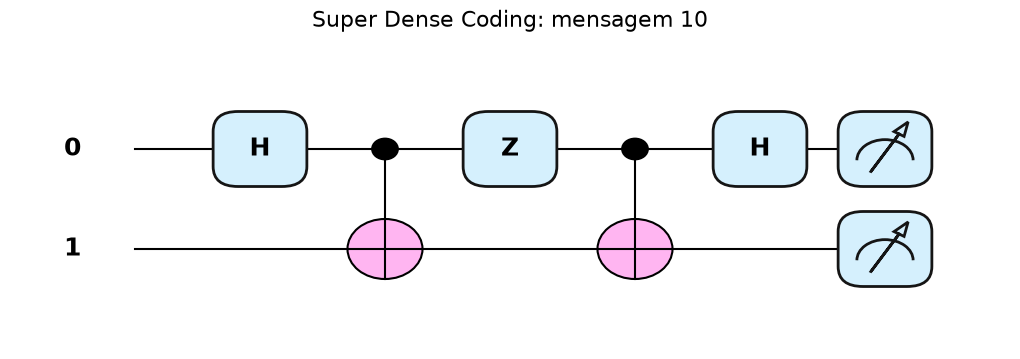

In [7]:
probabilities = super_dense_coding(message)
received_state = int(np.argmax(probabilities))
received_message = format(received_state, "02b")

print("Mensagem enviada:", message)
print("Mensagem recebida:", received_message)
print(f"Probabilidade: {probabilities[received_state]:.2%}")
fig, ax = qml.draw_mpl(super_dense_coding, style="pennylane", level="top", fontsize=18)(message)
fig.set_size_inches(10, 3)
ax.set_title(f"Super Dense Coding: mensagem {message}", fontsize=16, pad=16)
plt.show()

## Teste das quatro mensagens

In [8]:
results = np.array([super_dense_coding(message) for message in messages])

print(f"{'Enviada':<12}{'Recebida':<12}{'Probabilidade'}")
for sent_message, probabilities in zip(messages, results):
    received_state = int(np.argmax(probabilities))
    received_message = format(received_state, "02b")
    print(f"{sent_message:<12}{received_message:<12}{probabilities[received_state]:.2%}")

Enviada     Recebida    Probabilidade
00          00          100.00%
01          01          100.00%
10          10          100.00%
11          11          100.00%


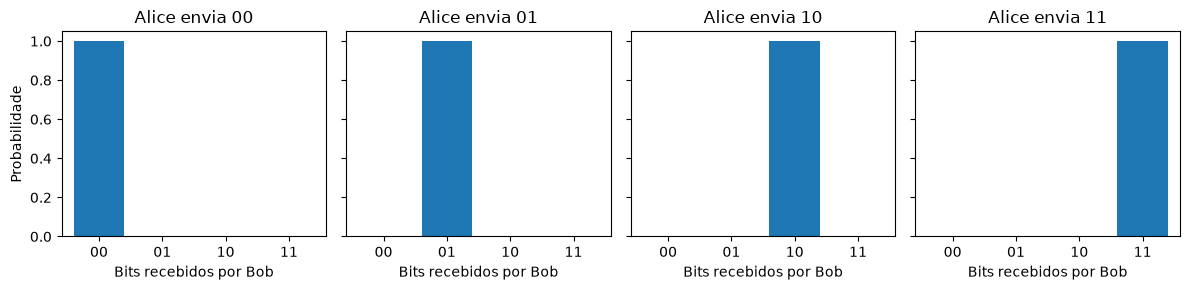

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=True)

for axis, sent_message, probabilities in zip(axes, messages, results):
    axis.bar(messages, probabilities)
    axis.set(title=f"Alice envia {sent_message}", xlabel="Bits recebidos por Bob", ylim=(0, 1.05))

axes[0].set_ylabel("Probabilidade")
plt.tight_layout()
plt.show()